In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [53]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [54]:
file_path = "/content/drive/MyDrive/DTCC/training/data_foundations/data/messy_ecommerce_100_rows.csv"

df = pd.read_csv(file_path)

df.head()

,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
0,ORD1001,C0016,Aarav Kumar,aarav.kumar95@gmail.com,2026-06-23,P102,Electronics,Bluetooth Headphones,2,1999,20,0.0,Net Banking,Delivered,Chennai,Tamil Nadu,600001,3198.4
1,ORD1002,C0002,Kabir Sharma,kabir.sharma26@gmail.com,2026-05-24,P110,Home,Desk Lamp,2,1299,0,0.0,Net Banking,Cancelled,Hyderabad,Telangana,500001,2598.0
2,ORD1003,C0052,Isha Kumar,NaN,2026-03-29,P104,Home,Water Bottle,2,349,20,80.0,Credit Card,Shipped,Hyderabad,Telangana,500001,638.4
3,ORD1004,C0025,Diya Reddy,diya.reddy6@gmail.com,2026-07-26,P106,Grocery,Coffee Powder,3,450,5,60.0,COD,Returned,Hyderabad,Telangana,500001,1342.5
4,ORD1005,C0006,Nikhil Das,nikhil.das25@gmail.com,2026-05-28,P102,Electronics,Bluetooth Headphones,NaN,1999,20,60.0,UPI,Delivered,Delhi,Delhi,110001,4857.6


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        99 non-null     object 
 1   customer_id     99 non-null     object 
 2   customer_name   99 non-null     object 
 3   email           99 non-null     object 
 4   order_date      99 non-null     object 
 5   product_id      100 non-null    object 
 6   category        100 non-null    object 
 7   product_name    100 non-null    object 
 8   quantity        99 non-null     object 
 9   unit_price      99 non-null     object 
 10  discount_pct    99 non-null     object 
 11  shipping_fee    99 non-null     float64
 12  payment_method  100 non-null    object 
 13  order_status    100 non-null    object 
 14  city            100 non-null    object 
 15  state           99 non-null     object 
 16  postal_code     100 non-null    object 
 17  total_amount    99 non-null     obje

In [56]:
df.shape

(100, 18)

In [57]:
df.isna().sum()

,0
order_id,1
customer_id,1
customer_name,1
email,1
order_date,1
product_id,0
category,0
product_name,0
quantity,1
unit_price,1


In [58]:
df.duplicated().sum()

np.int64(2)

In [59]:
df = df.dropna()

In [60]:
df = df.drop_duplicates()

In [61]:
df.isna().sum()

,0
order_id,0
customer_id,0
customer_name,0
email,0
order_date,0
product_id,0
category,0
product_name,0
quantity,0
unit_price,0


In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
df['total_amount'] = (
    df['total_amount']
    .astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace('rupees', '', case=False, regex=False)
    .str.strip()
)

df['total_amount'] = pd.to_numeric(
    df['total_amount'], errors='coerce'
)

print(df['total_amount'])


0     3198.4
1     2598.0
3     1342.5
5      374.1
6      422.5
       ...  
95    8036.0
96     956.8
97    2290.0
98    1839.1
99    1255.0
Name: total_amount, Length: 87, dtype: float64


In [64]:
print(df['total_amount'].mean())

14148.650574712647


In [65]:
print(df['total_amount'].median())

1555.0


In [66]:
print(df['product_name'].value_counts())

product_name
Running Shoes           13
Bluetooth Headphones    10
USB-C Cable             10
Water Bottle            10
Cotton T-Shirt           9
Coffee Powder            8
Python Basics            8
Desk Lamp                7
Wireless Mouse           5
Face Wash                5
bluetooth HEADPHONES     1
Wireless  Mouse          1
Name: count, dtype: int64


In [67]:
revenue_by_city = (
    df.groupby("city")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_city

,total_amount
city,
Delhi,1025949.95
Mumbai,45016.25
Hyderabad,44836.05
Pune,43387.90
Chennai,32293.40
Bengaluru,25066.50
Hyd,7122.15
HYDERABAD,2796.00
Chenn ai,2356.20


In [68]:

# Remove extra spaces and convert to lowercase
df['city'] = df['city'].str.strip().str.lower()

# Fix inconsistent city names
df['city'] = df['city'].replace({
    'hyd': 'hyderabad',
    'chenn ai': 'chennai',
    'bangalore': 'bengaluru'
})

# Capitalize city names
df['city'] = df['city'].str.title()


In [69]:
revenue_by_city = (
    df.groupby("city")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_city

,total_amount
city,
Delhi,1025949.95
Hyderabad,54754.20
Mumbai,46855.35
Pune,43387.90
Chennai,34649.60
Bengaluru,25335.60


In [70]:
revenue_summary = (
    df.groupby("city")
    .agg(
        TotalRevenue=("total_amount","sum"),
        AverageRevenue=("total_amount","mean"),
        OrderCounts=("order_id","count")
    )
    .sort_values("TotalRevenue",ascending=False)
)

revenue_summary

,TotalRevenue,AverageRevenue,OrderCounts
city,,,
Delhi,1025949.95,85495.829167,12
Hyderabad,54754.20,2737.710000,20
Mumbai,46855.35,2603.075000,18
Pune,43387.90,3099.135714,14
Chennai,34649.60,2665.353846,13
Bengaluru,25335.60,2533.560000,10


In [71]:
units_by_products = (
    df.groupby("product_name")
    .agg(
        TotalRevenue=("total_amount","sum"),
        AverageRevenue=("total_amount","mean"),
        OrderCounts=("order_id","count")
    )
    .sort_values("TotalRevenue",ascending=False)
)

units_by_products

,TotalRevenue,AverageRevenue,OrderCounts
product_name,,,
Desk Lamp,1023685.95,146240.850000,7
Running Shoes,88614.70,6816.515385,13
Bluetooth Headphones,44397.95,4439.795000,10
Python Basics,15708.10,1963.512500,8
Cotton T-Shirt,13937.50,1548.611111,9
Wireless Mouse,10839.70,2167.940000,5
USB-C Cable,9898.70,989.870000,10
Coffee Powder,9787.50,1223.437500,8
Water Bottle,9479.10,947.910000,10


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87 entries, 0 to 99
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        87 non-null     object 
 1   customer_id     87 non-null     object 
 2   customer_name   87 non-null     object 
 3   email           87 non-null     object 
 4   order_date      87 non-null     object 
 5   product_id      87 non-null     object 
 6   category        87 non-null     object 
 7   product_name    87 non-null     object 
 8   quantity        87 non-null     object 
 9   unit_price      87 non-null     object 
 10  discount_pct    87 non-null     object 
 11  shipping_fee    87 non-null     float64
 12  payment_method  87 non-null     object 
 13  order_status    87 non-null     object 
 14  city            87 non-null     object 
 15  state           87 non-null     object 
 16  postal_code     87 non-null     object 
 17  total_amount    87 non-null     float64
dt

In [73]:
numeric_cols = [
    'quantity',
    'unit_price',
    'discount_pct',
    'shipping_fee',
    'total_amount'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(
            r'[₹,%\s,]|(?i:rupees?)', '', regex=True
        ),
        errors='coerce'
    )

print(df[numeric_cols].dtypes)


quantity        float64
unit_price      float64
discount_pct    float64
shipping_fee    float64
total_amount    float64
dtype: object


In [74]:

print(df[numeric_cols].isnull().sum())


quantity        1
unit_price      1
discount_pct    1
shipping_fee    0
total_amount    0
dtype: int64


In [75]:
df[numeric_cols] = df[numeric_cols].dropna()

In [76]:
print(df[numeric_cols].isnull().sum())

quantity        3
unit_price      3
discount_pct    3
shipping_fee    3
total_amount    3
dtype: int64


In [77]:

corr = df[numeric_cols].corr()

print(corr)


              quantity  unit_price  discount_pct  shipping_fee  total_amount
quantity      1.000000   -0.153569      0.033963      0.133885     -0.124250
unit_price   -0.153569    1.000000      0.107818     -0.322946      0.056689
discount_pct  0.033963    0.107818      1.000000      0.068562     -0.073920
shipping_fee  0.133885   -0.322946      0.068562      1.000000     -0.151095
total_amount -0.124250    0.056689     -0.073920     -0.151095      1.000000


In [78]:
units_revenue_corr = df['unit_price'].corr(df['total_amount'])
units_revenue_corr

np.float64(0.056689402370749625)

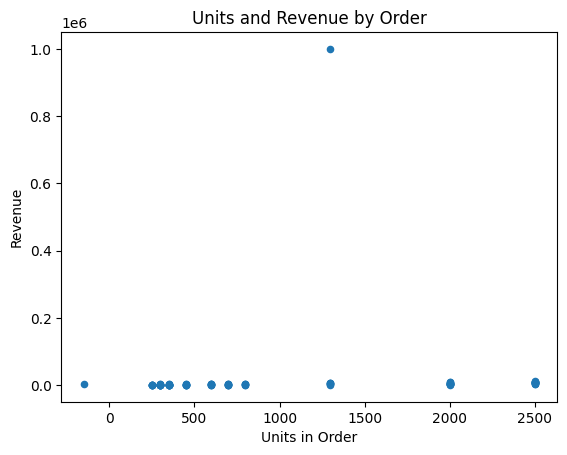

In [79]:
df.plot(
    kind = "scatter",
    x = "unit_price",
    y = "total_amount",
    title = "Units and Revenue by Order"
)

plt.xlabel("Units in Order")
plt.ylabel("Revenue")
plt.show()

In [80]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())


['order_id', 'customer_id', 'customer_name', 'email', 'order_date', 'product_id', 'category', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'shipping_fee', 'payment_method', 'order_status', 'city', 'state', 'postal_code', 'total_amount']


In [81]:
df

,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
0,ORD1001,C0016,Aarav Kumar,aarav.kumar95@gmail.com,2026-06-23,P102,Electronics,Bluetooth Headphones,2.0,1999.0,20.0,0.0,Net Banking,Delivered,Chennai,Tamil Nadu,600001,3198.4
1,ORD1002,C0002,Kabir Sharma,kabir.sharma26@gmail.com,2026-05-24,P110,Home,Desk Lamp,2.0,1299.0,0.0,0.0,Net Banking,Cancelled,Hyderabad,Telangana,500001,2598.0
3,ORD1004,C0025,Diya Reddy,diya.reddy6@gmail.com,2026-07-26,P106,Grocery,Coffee Powder,3.0,450.0,5.0,60.0,COD,Returned,Hyderabad,Telangana,500001,1342.5
5,ORD1006,C0006,Kiran Kumar,kiran.kumar82@gmail.com,2026-04-27,P104,Home,Water Bottle,1.0,349.0,10.0,60.0,Debit Card,Shipped,Chennai,Tamil Nadu,600001,374.1
6,ORD1007,C0043,Meera Singh,meera.singh94@gmail.com,2026-05-17,P106,Grocery,Coffee Powder,1.0,1999.0,15.0,40.0,Credit Card,Shipped,Bengaluru,Karnataka,560001,422.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,ORD1096,C0007,Sana Gupta,sana.gupta84@gmail.com,2026-04-15,P102,Electronics,Bluetooth Headphones,4.0,1999.0,0.0,40.0,Credit Card,Delivered,Delhi,Delhi,110001,8036.0
96,ORD1097,C0022,Kiran Kumar,kiran.kumar43@gmail.com,2026-08-07,P108,Electronics,USB-C Cable,4.0,299.0,20.0,0.0,Net Banking,Refunded,Delhi,Delhi,110001,956.8
97,ORD1098,C0035,Rahul Gupta,rahul.gupta88@gmail.com,2026-06-11,P106,Grocery,Coffee Powder,5.0,450.0,0.0,40.0,Debit Card,Shipped,Hyderabad,Telangana,500001,2290.0
98,ORD1099,C0049,Kabir Reddy,kabir.reddy39@gmail.com,2026-06-27,P102,Electronics,Bluetooth Headphones,1.0,1999.0,10.0,40.0,UPI,Delivered,Mumbai,Maharashtra,411001,1839.1


In [82]:

df['order_date'] = pd.to_datetime(
    df['order_date'], errors='coerce'
)

df['day'] = df['order_date'].dt.day
df['month'] = df['order_date'].dt.month
df['year'] = df['order_date'].dt.year

print(df[['order_date', 'day', 'month', 'year']].head())


  order_date   day  month    year
0 2026-06-23  23.0    6.0  2026.0
1 2026-05-24  24.0    5.0  2026.0
3 2026-07-26  26.0    7.0  2026.0
5 2026-04-27  27.0    4.0  2026.0
6 2026-05-17  17.0    5.0  2026.0


In [86]:
monthly_revenue = df.groupby(
    df['order_date'].dt.to_period('M')
)['total_amount'].sum()

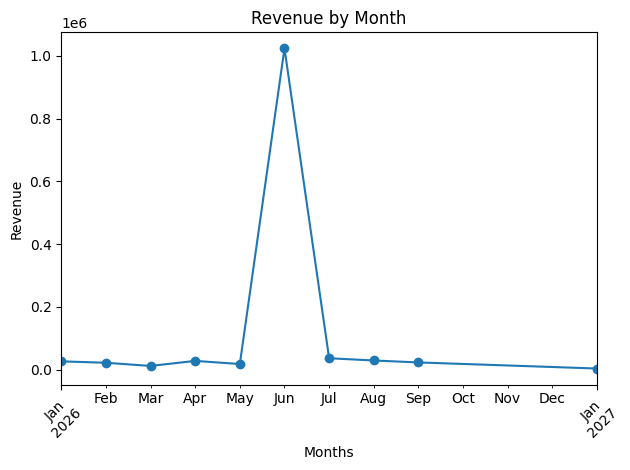

In [87]:
monthly_revenue.plot(
    kind = "line",
    marker = "o",
    title = "Revenue by Month"
)

plt.xlabel("Months")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

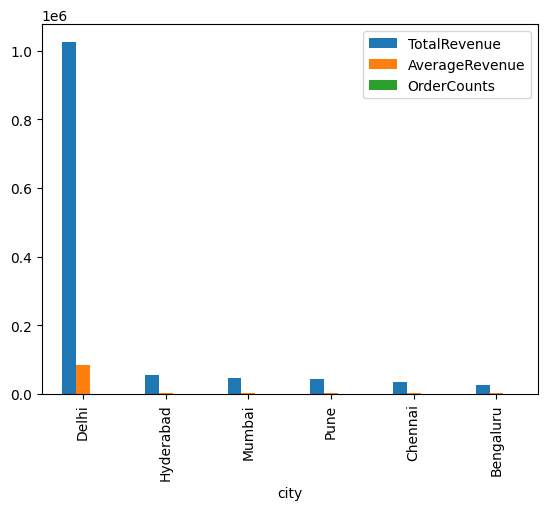

In [88]:
revenue_summary.plot(
    kind = "bar"
)
plt.show()

In [89]:

highest_revenue_orders = (
    df.sort_values('total_amount', ascending=False)
    [
        ['order_id', 'order_date', 'city',
         'product_name', 'quantity',
         'unit_price', 'discount_pct',
         'total_amount']
    ]
    .head(5)
)

highest_revenue_orders


,order_id,order_date,city,product_name,quantity,unit_price,discount_pct,total_amount
26,ORD1027,2026-06-02,Delhi,Desk Lamp,1.0,1299.0,0.0,999999.0
84,ORD1085,2026-09-06,Chennai,Running Shoes,5.0,2499.0,10.0,11325.5
14,ORD1015,2026-08-26,Bengaluru,Running Shoes,-2.0,2499.0,0.0,9996.0
50,ORD1051,2026-07-12,Pune,Running Shoes,4.0,2499.0,10.0,9056.4
78,ORD1079,2026-01-09,Mumbai,Bluetooth Headphones,5.0,1999.0,10.0,9055.5
